In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay)

pd.set_option('display.max_colwidth', None)
FILE_PATH = 'data/train.csv'

In [2]:
# load csv as df
df = pd.read_csv(FILE_PATH)

<positron-console-cell-2>:2: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.


In [3]:
print(df.shape)
df.head()

(1017209, 9)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [4]:
df.sample(10, random_state=42)

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
76435,616,7,2015-05-24,0,0,0,0,0,0
923026,592,2,2013-03-26,5548,710,1,1,0,1
731180,526,6,2013-09-14,7467,1150,1,0,0,0
790350,601,2,2013-07-23,3360,323,1,0,0,1
252134,953,1,2014-12-15,11414,853,1,1,0,0
425310,166,7,2014-06-15,0,0,0,0,0,0
666826,842,1,2013-11-11,14126,974,1,0,0,0
881992,813,4,2013-05-02,6299,718,1,1,0,0
783899,840,1,2013-07-29,10515,1364,1,1,0,1
540518,529,2,2014-03-04,7713,759,1,1,0,0


In [5]:
df['Store'].nunique()

1115

In [6]:
df.describe()

,Store,DayOfWeek,Sales,Customers,Open,Promo,SchoolHoliday
count,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06
mean,5.584297e+02,3.998341e+00,5.773819e+03,6.331459e+02,8.301067e-01,3.815145e-01,1.786467e-01
std,3.219087e+02,1.997391e+00,3.849926e+03,4.644117e+02,3.755392e-01,4.857586e-01,3.830564e-01
min,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.800000e+02,2.000000e+00,3.727000e+03,4.050000e+02,1.000000e+00,0.000000e+00,0.000000e+00
50%,5.580000e+02,4.000000e+00,5.744000e+03,6.090000e+02,1.000000e+00,0.000000e+00,0.000000e+00
75%,8.380000e+02,6.000000e+00,7.856000e+03,8.370000e+02,1.000000e+00,1.000000e+00,0.000000e+00
max,1.115000e+03,7.000000e+00,4.155100e+04,7.388000e+03,1.000000e+00,1.000000e+00,1.000000e+00


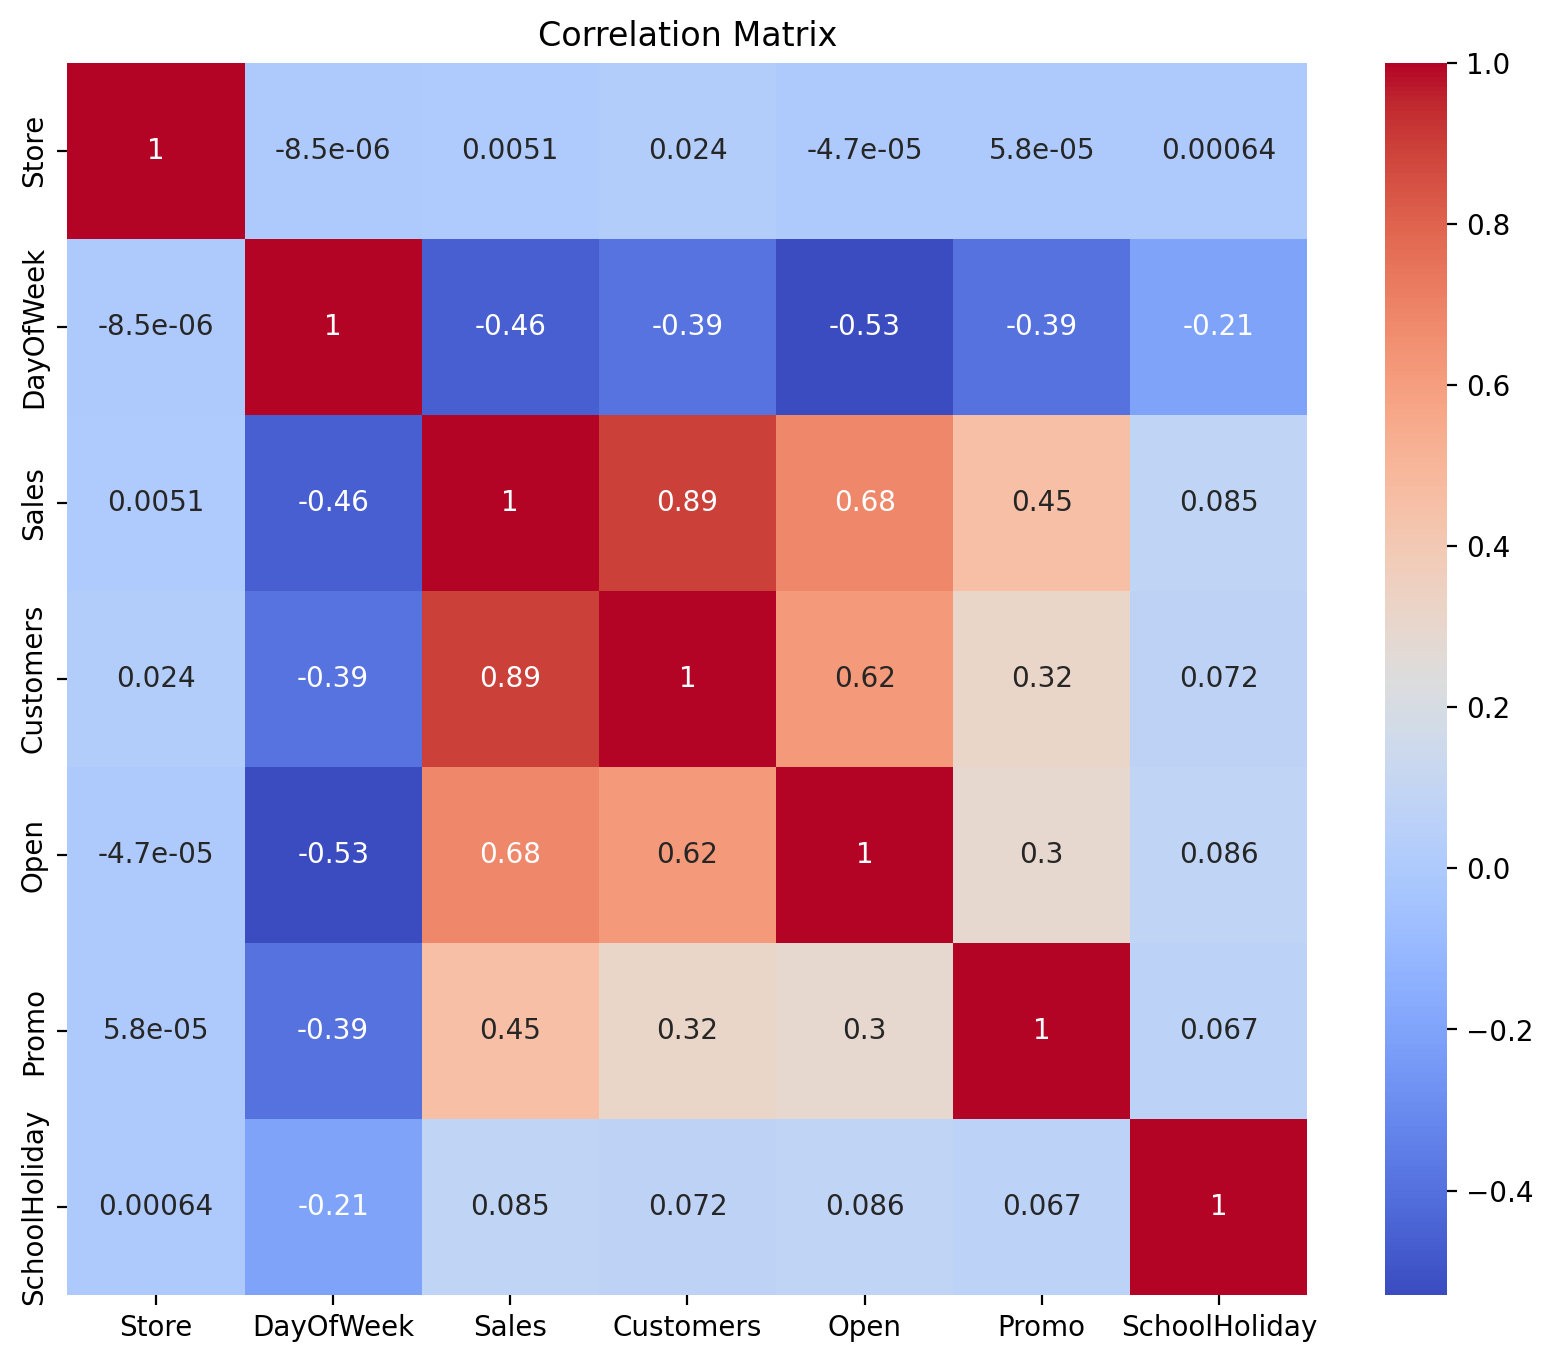

In [7]:
corr_matrix = df.corr(numeric_only=True)
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

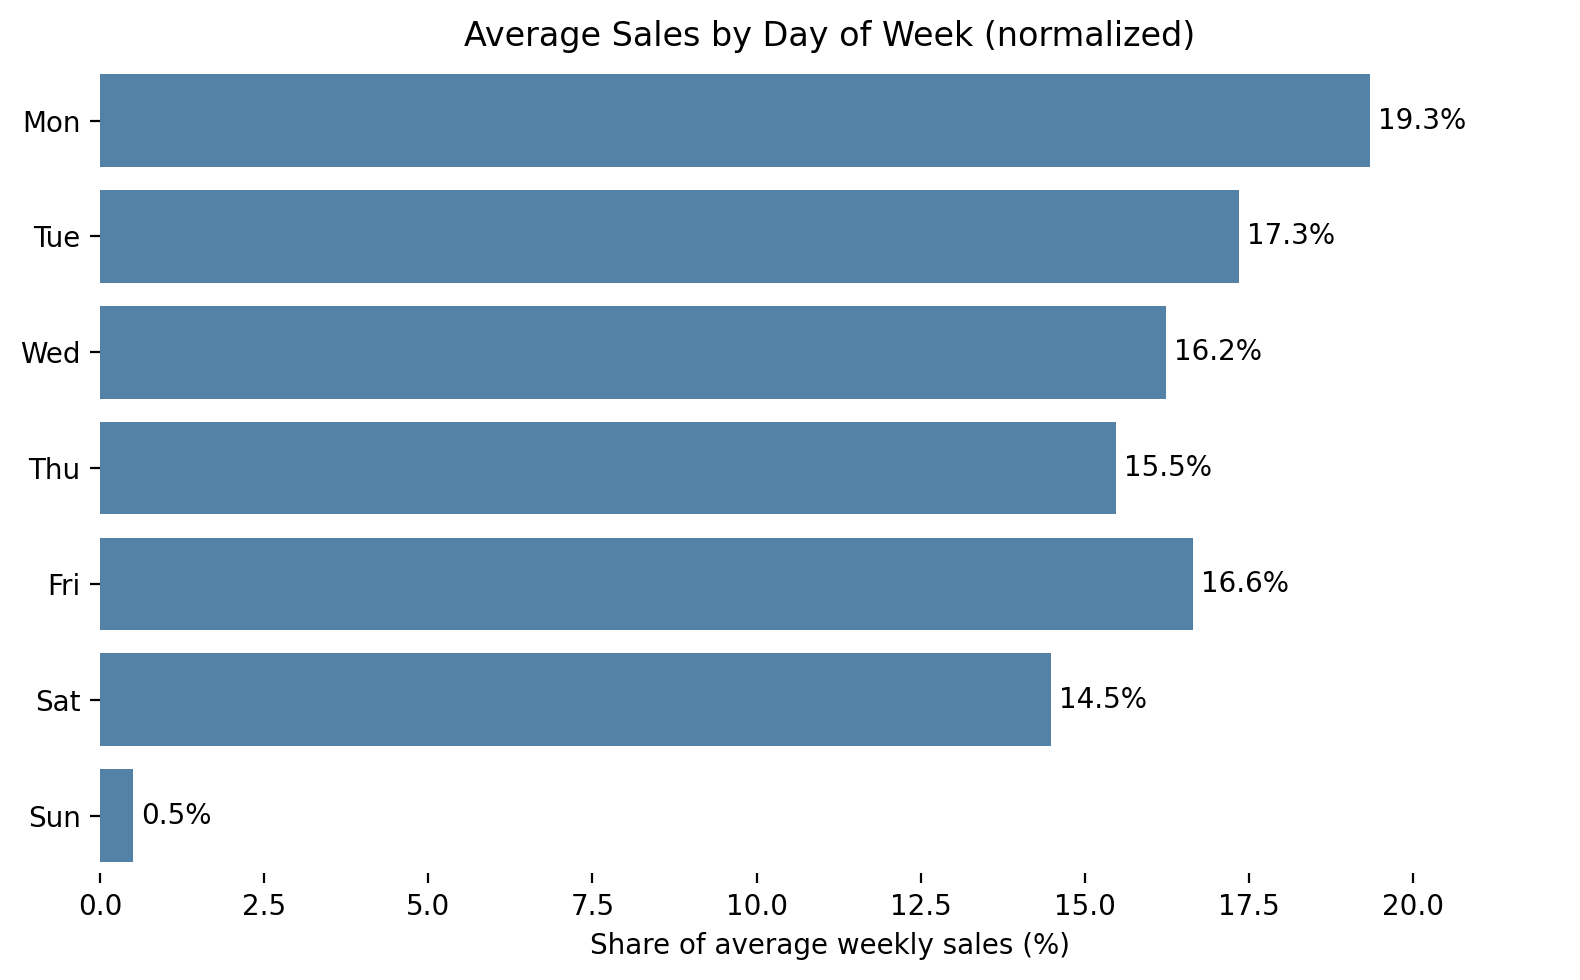

In [8]:
day_names = {1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat", 7: "Sun"}

daily = (
    df.groupby("DayOfWeek", as_index=False)["Sales"].mean()
      .assign(Day=lambda d: d["DayOfWeek"].map(day_names),
              Share=lambda d: d["Sales"] / d["Sales"].sum() * 100)
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=daily, y="Day", x="Share", order=list(day_names.values()),
            color="steelblue", ax=ax)

ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_xlabel("Share of average weekly sales (%)")
ax.set_ylabel("")
ax.set_title("Average Sales by Day of Week (normalized)")
sns.despine(left=True, bottom=True)
ax.set_xlim(0, daily["Share"].max() * 1.15)
plt.tight_layout()
plt.show()

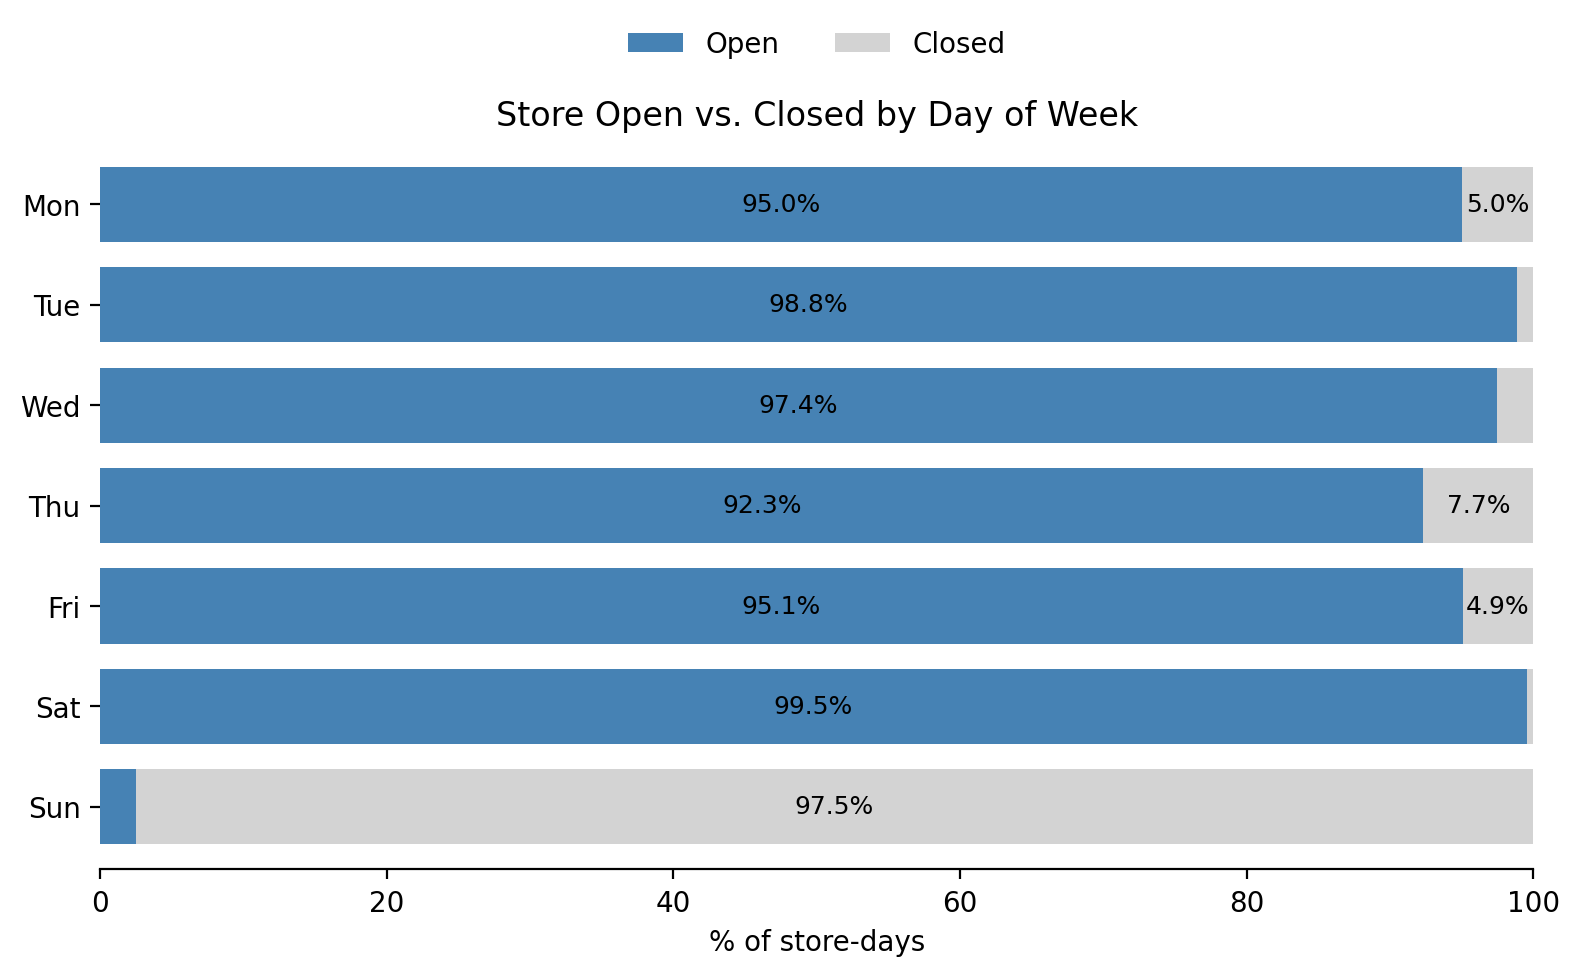

In [9]:
cross_tab = (
    pd.crosstab(df["DayOfWeek"], df["Open"], normalize="index")
      .mul(100)
      .rename(index=day_names, columns={0: "Closed", 1: "Open"})
      [["Open", "Closed"]]
      .iloc[::-1]
)

ax = cross_tab.plot(kind="barh", stacked=True, figsize=(8, 5),
                    color=["steelblue", "lightgray"], width=0.75)

for container in ax.containers:
    labels = [f"{w:.1f}%" if w > 4 else "" for w in container.datavalues]
    ax.bar_label(container, labels=labels, label_type="center", fontsize=9)

ax.set_xlabel("% of store-days")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.set_title("Store Open vs. Closed by Day of Week")
ax.legend(title="", loc="lower center", bbox_to_anchor=(0.5, 1.08), ncol=2, frameon=False)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

In [ ]:
# we can see why sunday has the smallest % of weekly sales: on sundays, stores aren't usually open!
# but if we didn't look into this we might've made a potentially false assumption 
# (people don't want to shop on sundays)

In [10]:
train = df[df["Date"] < "2015-05-01"]
test  = df[df["Date"] >= "2015-05-01"]

In [11]:
print(train.shape)
print(test.shape)

(914629, 9)
(102580, 9)
